# Exerciţiu laborator 8
## Programare probabilistă folosind PyMC

Un magazin este vizitat de $n$ clienţi într-o anumită zi. Numărul $Y$ de clienţi care cumpără un anumit produs e distribuit $\text{Binomial}(n, \theta)$, unde $\theta$ este probabilitatea ca un client să cumpere acel produs. Să presupunem că îl cunoaştem pe $\theta$ şi că distribuţia a priori pentru $n$ este $\text{Poisson}(10)$.

1. Folosiţi PyMC pentru a calcula distribuţia a posteriori pentru $n$ pentru toate combinaţiile de $Y \in \{0, 5, 10\}$ şi $\theta \in \{0.2, 0.5\}$. Folosiţi az.plot_posterior pentru a vizualiza toate rezultatele (ideal, într-o singură fereastră).

In [28]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats

Ys = np.array([0, 5, 10])
thetas = np.array([0.01, 0.1, 0.2, 0.5, 0.8, 0.99])
coords = {"Y": Ys, "theta": thetas}

In [29]:
with pm.Model(coords = coords) as model:
    n = pm.Poisson("n", mu = 10, dims = ("Y", "theta"))
    Y = pm.Binomial("Y_obs", n = n, p = thetas, observed = np.repeat(Ys[:, None], len(thetas), axis = 1), dims = ("Y", "theta"))

print(model.str_repr())

    n ~ Poisson(10)
Y_obs ~ Binomial(n, <constant>)


In [30]:
with model:
    idata = pm.sample(5000, tune = 1000, random_seed = 67, progressbar = False, chains = 4)

az.summary(idata, ci_kind = "hdi", ci_prob = 0.94)

Multiprocess sampling (4 chains in 4 jobs)
Metropolis: [n]
Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 3 seconds.


,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"n[0, 0.01]",9.78,3.16,4,15,4618,4999,1.00,0.047,0.034
"n[0, 0.1]",8.99,2.99,3,14,4652,4860,1.00,0.044,0.032
"n[0, 0.2]",8.04,2.81,3,13,4715,4892,1.00,0.041,0.033
"n[0, 0.5]",5.01,2.27,1,9,4233,4745,1.00,0.035,0.027
"n[0, 0.8]",2.03,1.41,0,4,4111,3914,1.00,0.022,0.017
"n[0, 0.99]",0.1,0.31,0,1,3420,3530,1.00,0.0054,0.0092
"n[5, 0.01]",14.78,3.11,9,20,4500,5338,1.00,0.046,0.032
"n[5, 0.1]",14.01,3.03,8,19,3955,4572,1.00,0.049,0.04
"n[5, 0.2]",12.96,2.85,8,18,4216,4991,1.00,0.044,0.028
"n[5, 0.5]",9.9,2.16,6,14,4124,5105,1.00,0.034,0.023


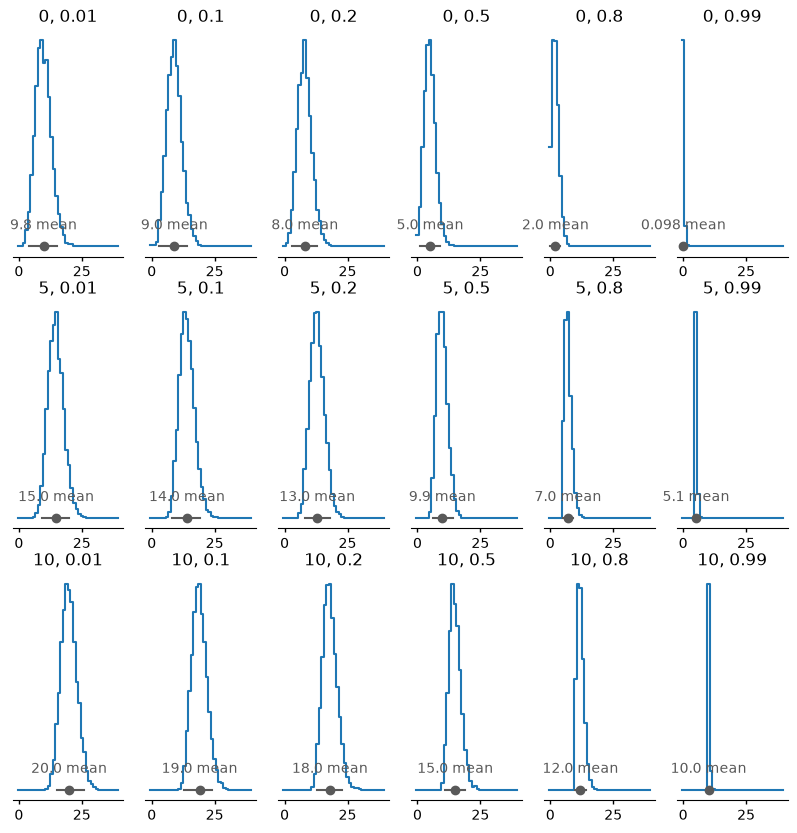

In [31]:
pc = az.PlotCollection.grid(idata.posterior.dataset, rows = ["Y"], cols = ["theta"], figure_kwargs = {"figsize": (10, 10)})

az.plot_dist(
    idata,
    var_names = ["n"],
    kind = "hist",
    point_estimate = "mean",
    ci_kind = "hdi",
    ci_prob = 0.94,
    plot_collection = pc,
    labeller = az.labels.NoVarLabeller(),
    stats = {"dist": {"bins": np.broadcast_to(np.arange(41) - 0.5, (len(Ys), len(thetas), 41))}},
)
plt.show()

2. Explicaţi efectul lui $Y$ şi $\theta$ asupra distribuţiei a posteriori.

In [32]:
post_n = idata.posterior["n"]

for y in Ys:
    for t in thetas:
        exact = stats.poisson(10 * (1 - t), loc = y)
        s = post_n.sel(Y = y, theta = t)
        print(f"Y = {y:2d}, θ = {t}: media exacta = {exact.mean():5.2f}, sd exact = {exact.std():.3f} | media MCMC = {s.mean().item():5.2f}, sd MCMC = {s.std().item():.3f}")

Y =  0, θ = 0.01: media exacta =  9.90, sd exact = 3.146 | media MCMC =  9.78, sd MCMC = 3.156
Y =  0, θ = 0.1: media exacta =  9.00, sd exact = 3.000 | media MCMC =  8.99, sd MCMC = 2.994
Y =  0, θ = 0.2: media exacta =  8.00, sd exact = 2.828 | media MCMC =  8.04, sd MCMC = 2.814
Y =  0, θ = 0.5: media exacta =  5.00, sd exact = 2.236 | media MCMC =  5.01, sd MCMC = 2.269
Y =  0, θ = 0.8: media exacta =  2.00, sd exact = 1.414 | media MCMC =  2.03, sd MCMC = 1.414
Y =  0, θ = 0.99: media exacta =  0.10, sd exact = 0.316 | media MCMC =  0.10, sd MCMC = 0.312
Y =  5, θ = 0.01: media exacta = 14.90, sd exact = 3.146 | media MCMC = 14.78, sd MCMC = 3.109
Y =  5, θ = 0.1: media exacta = 14.00, sd exact = 3.000 | media MCMC = 14.01, sd MCMC = 3.028
Y =  5, θ = 0.2: media exacta = 13.00, sd exact = 2.828 | media MCMC = 12.96, sd MCMC = 2.851
Y =  5, θ = 0.5: media exacta = 10.00, sd exact = 2.236 | media MCMC =  9.90, sd MCMC = 2.163
Y =  5, θ = 0.8: media exacta =  7.00, sd exact = 1.414 |

In [33]:
for y in Ys:
    for t in thetas:
        Y_prior = stats.poisson(10 * t)
        print(f"Y = {y:2d}, θ = {t}: Y a priori ~ Poisson({10 * t:g}), P(Y = {y:2d}) = {Y_prior.pmf(y):.2e}, P(Y >= {y:2d}) = {Y_prior.sf(y - 1):.2e}")

Y =  0, θ = 0.01: Y a priori ~ Poisson(0.1), P(Y =  0) = 9.05e-01, P(Y >=  0) = 1.00e+00
Y =  0, θ = 0.1: Y a priori ~ Poisson(1), P(Y =  0) = 3.68e-01, P(Y >=  0) = 1.00e+00
Y =  0, θ = 0.2: Y a priori ~ Poisson(2), P(Y =  0) = 1.35e-01, P(Y >=  0) = 1.00e+00
Y =  0, θ = 0.5: Y a priori ~ Poisson(5), P(Y =  0) = 6.74e-03, P(Y >=  0) = 1.00e+00
Y =  0, θ = 0.8: Y a priori ~ Poisson(8), P(Y =  0) = 3.35e-04, P(Y >=  0) = 1.00e+00
Y =  0, θ = 0.99: Y a priori ~ Poisson(9.9), P(Y =  0) = 5.02e-05, P(Y >=  0) = 1.00e+00
Y =  5, θ = 0.01: Y a priori ~ Poisson(0.1), P(Y =  5) = 7.54e-08, P(Y >=  5) = 7.67e-08
Y =  5, θ = 0.1: Y a priori ~ Poisson(1), P(Y =  5) = 3.07e-03, P(Y >=  5) = 3.66e-03
Y =  5, θ = 0.2: Y a priori ~ Poisson(2), P(Y =  5) = 3.61e-02, P(Y >=  5) = 5.27e-02
Y =  5, θ = 0.5: Y a priori ~ Poisson(5), P(Y =  5) = 1.75e-01, P(Y >=  5) = 5.60e-01
Y =  5, θ = 0.8: Y a priori ~ Poisson(8), P(Y =  5) = 9.16e-02, P(Y >=  5) = 9.00e-01
Y =  5, θ = 0.99: Y a priori ~ Poisson(9.9), 

In [34]:
with pm.Model(coords = coords) as model_lam:
    lam = pm.Exponential("lam", lam = 1 / 10, dims = ("Y", "theta"))
    n_lam = pm.Poisson("n", mu = lam, dims = ("Y", "theta"))
    Y_lam = pm.Binomial("Y_obs", n = n_lam, p = thetas, observed = np.repeat(Ys[:, None], len(thetas), axis = 1), dims = ("Y", "theta"))
    idata_lam = pm.sample(5000, tune = 2000, target_accept = 0.99, random_seed = 67, progressbar = False)

az.summary(idata_lam, var_names = ["n"], ci_kind = "hdi", ci_prob = 0.94)

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>NUTS: [lam]
>Metropolis: [n]
Sampling 4 chains for 2_000 tune and 5_000 draw iterations (8_000 + 20_000 draws total) took 15 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


,mean,sd,hdi94_lb,hdi94_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
"n[0, 0.01]",9,9,0,26,350,473,1.02,0.51,0.57
"n[0, 0.1]",4.5,5,0,14,587,787,1.00,0.22,0.27
"n[0, 0.2]",2.7,3.3,0,8,960,1358,1.00,0.11,0.22
"n[0, 0.5]",0.88,1.3,0,3,1603,1910,1.00,0.034,0.043
"n[0, 0.8]",0.23,0.55,0,1,1647,1850,1.00,0.014,0.022
"n[0, 0.99]",0.01,0.1,0,0,2347,2347,1.00,0.0021,0.01
"n[5, 0.01]",60,24,19,100,391,576,1.01,1.2,1
"n[5, 0.1]",32.1,11.9,11,53,710,1111,1.00,0.45,0.28
"n[5, 0.2]",21,7.8,7,35,1003,1477,1.01,0.25,0.18
"n[5, 0.5]",10,2.92,5,15,2272,2946,1.00,0.061,0.044


n - Y + Z. Unde Z este numarul de clienți care intră și nu cumpară nimic.

fiecare client este "sampled" independent -> Y si Z sunt variabile independente

Dacă îl știm pe Y, atunci Y este fixat, dar în continuare nu știm nimic despre Z, în schimb, știm că se va respecta mereu următoarea egalitate: $Y + Z = n$

În contextul condiționării după Y (îl cunoaștem pe Y), Y este constantă => avem bijecție între valorile lui Z si n (unul îl determină pe celălalt)

p(Z fails | Y) = p(Y + Z trials | Y) = p(n trials | Y)

$$p(n | Y) \propto \underbrace{\binom{n}{Y} \theta^Y (1 - \theta)^{n - Y}}_{\text{verosimilitate}} \cdot \underbrace{e^{-10} \frac{10^n}{n!}}_{\text{a priori}} = \frac{\theta^Y e^{-10}\, 10^Y}{Y!} \cdot \frac{[10(1 - \theta)]^{n - Y}}{(n - Y)!} \propto \frac{[10(1 - \theta)]^{n - Y}}{(n - Y)!}$$

Deci $Z | Y$ ~ $ Poisson(10 * (1 - \theta))$

n | Y ~ Z | Y + Y

de aici se deducem si ce se observa pe grafic, anume ca Y doar mută distribuția st <-> dr, iar $\theta$ e cel care chiar îi schimbă forma